# Lab 1 — Image visualisation, composites and spectral indices (Python)

[Lab 1](https://danielm09.github.io/remotesensing/labs/lab1/), AI-generated Python port made by Claude Opus 5.5. 

### Layout
The notebook should be located next to the two lab folders with data from [here](https://liveeduisegiunl-my.sharepoint.com/:f:/g/personal/dmoraes_novaims_unl_pt/IgBDtZ4KQHoiSKZa7MNO99oyAeCGmwTEzOwbiw53tMEEh2k), so the overall layout follows the structure:

```
rs/
├── Lab1_python.ipynb
├── Images/          T29SMC_20260403T112109_B0{2,3,4,8}_10m.jp2
├── Exercise/        T29TNE_20250823T112131_B0{2,3,4,8}_10m.jp2, ..._B12_20m.jp2, burned_areas_2025.shp
├── pyproject.toml   dependency requirements for the uv
└── outputs/         created here

```

The data folders are ignored in .gitignore. 

### Setup
To run it, you need python3.11+, gdal, and uv. Run with 
```
uv sync
uv run jupyter lab
```

### Data 

It uses Sentinel-2 L2A data, more in [documentation](https://docs.planet.com/data/public-data/copernicus/sentinel-2/).


The thing Claude found:
> **The L2A offset, which the ArcGIS version skips.** Since processing baseline 04.00 (Jan 2022), Sentinel-2 L2A
> digital numbers carry a +1000 offset: **reflectance = (DN − 1000) / 10 000**. The B08 histogram in §4 shows it: open
> water sits just above DN 1000, not near 0. ArcGIS's NDVI tool and band arithmetic work on raw DNs. For true
> reflectances *n*, *r*, that turns NDVI into (*n* − *r*) / (*n* + *r* + 0.2), which pulls every normalised-difference
> index toward zero. EVI, with its additive constants, comes out simply wrong. This notebook converts to reflectance first.
> Set `BOA_ADD_OFFSET = 0` to reproduce the ArcGIS numbers. *Why the offset matters* (after NDVI) measures the gap.


In [114]:
import os
os.environ.setdefault("GDAL_NUM_THREADS", "ALL_CPUS")   # faster JPEG 2000 decoding

import re
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.plot import plotting_extent
from rasterio.transform import array_bounds
from rasterio.warp import reproject, transform_bounds, transform as warp_xy
from rasterio.windows import Window, from_bounds, bounds as window_bounds

# --- paths ---------------------------------------------------------------------------------
ROOT    = Path(os.environ.get("LAB1_ROOT", "."))   # folder that contains Images/ and Exercise/
IMG_DIR = ROOT / "Images"
EX_DIR  = ROOT / "Exercise"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

# --- Sentinel-2 L2A radiometry (processing baseline >= 04.00) --------------------------------
BOA_ADD_OFFSET = -1000    # set to 0 to reproduce the ArcGIS (raw-DN) index values
QUANT          = 10_000
NODATA         = 0        # Sentinel-2 no-data DN

PREVIEW_MAX = 1500        # longest side, in pixels, of on-screen previews
plt.rcParams.update({"figure.dpi": 90, "image.interpolation": "nearest"})

In [115]:
S2 = {  # band: (name, central wavelength in nm, native resolution in m)
    "B01": ("Coastal", 443, 60),   "B02": ("Blue", 490, 10),        "B03": ("Green", 560, 10),
    "B04": ("Red", 665, 10),       "B05": ("Red edge 1", 705, 20),  "B06": ("Red edge 2", 740, 20),
    "B07": ("Red edge 3", 783, 20), "B08": ("NIR", 842, 10),        "B8A": ("Narrow NIR", 865, 20),
    "B09": ("Water vapour", 945, 60), "B10": ("Cirrus", 1375, 60),
    "B11": ("SWIR 1", 1610, 20),   "B12": ("SWIR 2", 2190, 20),
}

BAND_RE = re.compile(r"(?:^|[_.-])(B0[1-9]|B1[0-2]|B8A|SCL)(?=[_.-])", re.I)
TILE_RE = re.compile(r"T\d{2}[A-Z]{3}")


def pixel_size(path):
    with rasterio.open(path) as src:
        return src.res[0]


def find_bands(folder, exts=(".jp2", ".tif", ".tiff")):
    """Locate Sentinel-2 band files -> {band: {tile: path}}, sorted by wavelength.
    If a band exists at several resolutions (e.g. a full .SAFE folder), the finest wins."""
    found = defaultdict(dict)
    for p in sorted(Path(folder).rglob("*")):
        if p.suffix.lower() not in exts or p.name.upper().startswith("MSK_"):
            continue
        if not (m := BAND_RE.search(p.name)):
            continue
        band = m.group(1).upper()
        tile = t.group(0) if (t := TILE_RE.search(p.name)) else "tile"
        prev = found[band].get(tile)
        if prev is None or pixel_size(p) < pixel_size(prev):
            found[band][tile] = p
    order = list(S2) + ["SCL"]
    return {b: found[b] for b in sorted(found, key=order.index)}


def to_reflectance(dn):
    """uint16 DN -> float32 surface reflectance; no-data (0) -> NaN."""
    refl = (dn.astype("float32") + BOA_ADD_OFFSET) / QUANT
    refl[dn == NODATA] = np.nan
    return refl


def nd(a, b):
    """Normalised difference (a - b) / (a + b), clipped to [-1, 1]
    (values outside occur only where L2A reflectance is slightly negative, e.g. dark water)."""
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.clip((a - b) / (a + b), -1, 1)


def read_preview(path, indexes, max_size=PREVIEW_MAX):
    """Decimated read for display. GDAL serves it from overviews / JPEG 2000 resolution
    levels when the file has them -- exactly what pyramids are for.
    Returns (masked array [bands, rows, cols], imshow extent)."""
    with rasterio.open(path) as src:
        f = max(1, int(np.ceil(max(src.width, src.height) / max_size)))
        arr = src.read(list(indexes), out_shape=(len(indexes), src.height // f, src.width // f),
                       resampling=Resampling.average)
        b = src.bounds
    return np.ma.masked_equal(arr, NODATA), (b.left, b.right, b.bottom, b.top)


def read_zoom(path, indexes, lon, lat, half_size_m=3000):
    """Full-resolution window of +-half_size_m around (lon, lat)."""
    with rasterio.open(path) as src:
        (x,), (y,) = warp_xy("EPSG:4326", src.crs, [lon], [lat])
        win = from_bounds(x - half_size_m, y - half_size_m, x + half_size_m, y + half_size_m, src.transform)
        win = win.round_offsets().round_lengths().intersection(Window(0, 0, src.width, src.height))
        arr = src.read(list(indexes), window=win)
        left, bottom, right, top = window_bounds(win, src.transform)
    return np.ma.masked_equal(arr, NODATA), (left, right, bottom, top)


def stretch(arr, method="percent_clip", pmin=2.0, pmax=98.0, n_std=2.0):
    """Per-band contrast stretch to [0, 1] -- the 'Stretch type' options of ArcGIS symbology.
    none: raw 16-bit range (0-65535) | minmax | percent_clip (pmin/pmax) | std (mean +- n_std * sd)"""
    a = np.ma.masked_invalid(np.ma.filled(np.ma.asarray(arr).astype("float32"), np.nan))
    out = []
    for band in a:
        v = band.compressed()
        if method == "none":
            lo, hi = 0.0, 65535.0
        elif method == "minmax":
            lo, hi = v.min(), v.max()
        elif method == "percent_clip":
            lo, hi = np.percentile(v, [pmin, pmax])
        elif method == "std":
            lo, hi = v.mean() - n_std * v.std(), v.mean() + n_std * v.std()
        else:
            raise ValueError(method)
        out.append(np.ma.clip((band - lo) / (hi - lo), 0, 1))
    return np.ma.stack(out)


def as_rgba(rgb):
    """[3, rows, cols] masked array in [0, 1] -> [rows, cols, 4] image with no-data transparent."""
    data = np.moveaxis(np.ma.filled(rgb, 0.0), 0, -1)
    alpha = (~np.ma.getmaskarray(rgb).any(axis=0))[..., None].astype("float32")
    return np.concatenate([data, alpha], axis=-1)


def show(arr, extent, ax=None, title=None, colorbar=True, **kw):
    """imshow a (possibly full-resolution) 2-D array, decimated for display."""
    f = max(1, int(np.ceil(max(arr.shape) / PREVIEW_MAX)))
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(arr[::f, ::f], extent=extent, **kw)
    if colorbar:
        plt.colorbar(im, ax=ax, shrink=0.75)
    if title:
        ax.set_title(title)
    return ax


def write_tif(path, arr, crs, transform, nodata, compress="lzw", overviews=True,
              descriptions=(), ov_resampling=Resampling.average):
    """Write a [bands, rows, cols] or [rows, cols] array as GeoTIFF; optional internal overviews."""
    arr = arr[None] if arr.ndim == 2 else arr
    profile = dict(driver="GTiff", count=arr.shape[0], height=arr.shape[1], width=arr.shape[2],
                   dtype=arr.dtype.name, crs=crs, transform=transform, nodata=nodata, BIGTIFF="IF_SAFER")
    if compress:
        predictor = 3 if np.issubdtype(arr.dtype, np.floating) else 2
        profile.update(compress=compress, predictor=predictor, tiled=True, blockxsize=512, blockysize=512)
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(arr)
        for i, d in enumerate(descriptions, start=1):
            dst.set_band_description(i, d)
        if overviews:
            dst.build_overviews([2, 4, 8, 16, 32, 64], ov_resampling)
            dst.update_tags(ns="rio_overview", resampling=ov_resampling.name)
    return Path(path)

## 1. Open the images
ArcGIS: drag the `.jp2` files onto the map. Here: find them and open them with rasterio. Opening only reads the
header; pixels are read later, on demand.

In [6]:
bands = {b: next(iter(t.values())) for b, t in find_bands(IMG_DIR).items() if b in S2}
for b, p in bands.items():
    print(f"{b}  {S2[b][0]:<6} {p.name}")

B02  Blue   T29SMC_20260403T112109_B02_10m.jp2
B03  Green  T29SMC_20260403T112109_B03_10m.jp2
B04  Red    T29SMC_20260403T112109_B04_10m.jp2
B08  NIR    T29SMC_20260403T112109_B08_10m.jp2


In [8]:
S2

{'B01': ('Coastal', 443, 60),
 'B02': ('Blue', 490, 10),
 'B03': ('Green', 560, 10),
 'B04': ('Red', 665, 10),
 'B05': ('Red edge 1', 705, 20),
 'B06': ('Red edge 2', 740, 20),
 'B07': ('Red edge 3', 783, 20),
 'B08': ('NIR', 842, 10),
 'B8A': ('Narrow NIR', 865, 20),
 'B09': ('Water vapour', 945, 60),
 'B10': ('Cirrus', 1375, 60),
 'B11': ('SWIR 1', 1610, 20),
 'B12': ('SWIR 2', 2190, 20)}

## 2. Inspect the image properties
Width, height, data type, compression, CRS and cell size come from the file header. The JPEG 2000 files are wavelet-compressed, so they're about 2.5× smaller than the raw pixel data.

In [41]:
rows = []
for b, p in bands.items():
    with rasterio.open(p) as src:
        rows.append({
            "band": b, "name": S2[b][0], "wavelength_nm": S2[b][1],
            "width": src.width, "height": src.height, "dtype": src.dtypes[0],
            "pixel_size_m": src.res, "crs": src.crs.to_string(), "driver": src.driver,
            "nodata": src.nodata, "file_MB": round(p.stat().st_size / 1e6, 1),
            "raw_MB": round(src.width * src.height * np.dtype(src.dtypes[0]).itemsize / 1e6, 1),
        })
pd.DataFrame(rows).set_index("band")

,name,wavelength_nm,width,height,dtype,pixel_size_m,crs,driver,nodata,file_MB,raw_MB
band,,,,,,,,,,,
B02,Blue,490,10980,10980,uint16,"(10.0, 10.0)",EPSG:32629,JP2OpenJPEG,None,95.6,241.1
B03,Green,560,10980,10980,uint16,"(10.0, 10.0)",EPSG:32629,JP2OpenJPEG,None,92.4,241.1
B04,Red,665,10980,10980,uint16,"(10.0, 10.0)",EPSG:32629,JP2OpenJPEG,None,89.8,241.1
B08,NIR,842,10980,10980,uint16,"(10.0, 10.0)",EPSG:32629,JP2OpenJPEG,None,89.3,241.1


Let's check the CRS and bounding box coordinates. 

In [46]:
import pyproj

with rasterio.open(bands["B08"]) as src:
    CRS, BOUNDS, TRANSFORM = src.crs, src.bounds, src.transform
# print(CRS, BOUNDS)
west, south, east, north = transform_bounds(CRS, "EPSG:4326", *BOUNDS)

print("Affine transform (pixel width, row rotation, x origin / column rotation, pixel height, y origin):")
print(TRANSFORM)
print(f"\nCRS     {CRS}  -  {pyproj.CRS(CRS).name}")
print(f"Size    {BOUNDS.right - BOUNDS.left:,.0f} m x {BOUNDS.top - BOUNDS.bottom:,.0f} m")
print(f"Lon     {west:.3f} .. {east:.3f}")
print(f"Lat     {south:.3f} .. {north:.3f}")

Affine transform (pixel width, row rotation, x origin / column rotation, pixel height, y origin):
| 10.00, 0.00, 399960.00|
| 0.00,-10.00, 4300020.00|
| 0.00, 0.00, 1.00|

CRS     EPSG:32629  -  WGS 84 / UTM zone 29N
Size    109,800 m x 109,800 m
Lon     -10.153 .. -8.888
Lat     37.854 .. 38.849


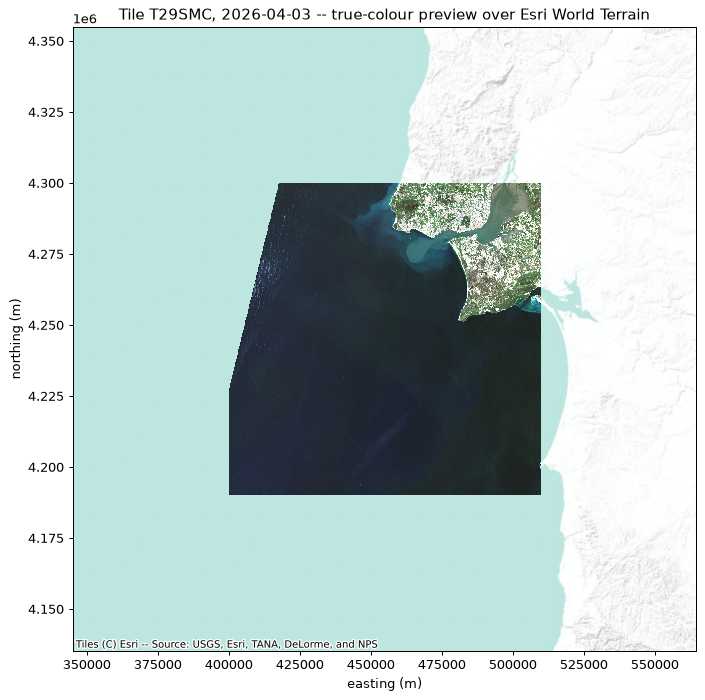

In [38]:
import contextily as ctx

# True-colour preview straight from the JPEG 2000 files (uses their built-in resolution levels)
previews = [read_preview(bands[b], [1]) for b in ("B04", "B03", "B02")]
rgb_raw, extent = np.ma.concatenate([p[0] for p in previews]), previews[0][1]

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(as_rgba(stretch(rgb_raw)), extent=extent, alpha=0.85, zorder=2)
pad = 0.5 * (extent[1] - extent[0])
ax.set_xlim(extent[0] - pad, extent[1] + pad)
ax.set_ylim(extent[2] - pad, extent[3] + pad)
try:
    ctx.add_basemap(ax, crs=CRS.to_string(), source=ctx.providers.Esri.WorldTerrain, zorder=1)
except Exception as err:
    print(f"Basemap not available here ({type(err).__name__})")

ax.set_title("Tile T29SMC, 2026-04-03 -- true-colour preview over Esri World Terrain")
ax.set_xlabel("easting (m)"); ax.set_ylabel("northing (m)");

**Questions**
1. What is the spatial resolution of the image?
2. Where on Earth is it, and does it line up with the basemap?

*Your answers:*

## 3. Inspect pixel values
ArcGIS: click pixels with the *Explore* tool. Here: sample the four bands at named points (edit `POINTS` freely) and
plot their spectral profiles.

For click/hover inspection, `pip install ipympl`, run `%matplotlib widget`, then re-run any plot cell. The toolbar
shows the x, y and value under the cursor.

In [49]:
%matplotlib widget

In [53]:
POINTS = {                        # name: (lon, lat) -- edit or add your own
    "Atlantic Ocean":       (-9.600, 38.600),
    "Tagus estuary":        (-9.050, 38.750),
    "Monsanto forest park": (-9.195, 38.730),
    "Baixa (dense urban)":  (-9.137, 38.711),
    "Arrábida hills":       (-8.980, 38.490),
}
lons, lats = zip(*POINTS.values())
xs, ys = warp_xy("EPSG:4326", CRS, lons, lats)
inside = [BOUNDS.left <= x <= BOUNDS.right and BOUNDS.bottom <= y <= BOUNDS.top for x, y in zip(xs, ys)]

dn = {}
for b, p in bands.items():
    with rasterio.open(p) as src:
        dn[b] = [int(v[0]) if ok else np.nan for v, ok in zip(src.sample(zip(xs, ys)), inside)]
dn = pd.DataFrame(dn, index=list(POINTS)).replace(NODATA, np.nan)
refl = (dn + BOA_ADD_OFFSET) / QUANT
display(dn.astype("Int64").style.set_caption("Raw DN"), refl.style.format("{:.3f}").set_caption("Reflectance"))

,B02,B03,B04,B08
Atlantic Ocean,1249,1147,1069,1079
Tagus estuary,1499,1673,1530,1129
Monsanto forest park,1321,1508,1345,3905
Baixa (dense urban),2005,2165,2476,2851
Arrábida hills,1274,1454,1341,3472


,B02,B03,B04,B08
Atlantic Ocean,0.025,0.015,0.007,0.008
Tagus estuary,0.050,0.067,0.053,0.013
Monsanto forest park,0.032,0.051,0.035,0.290
Baixa (dense urban),0.101,0.117,0.148,0.185
Arrábida hills,0.027,0.045,0.034,0.247


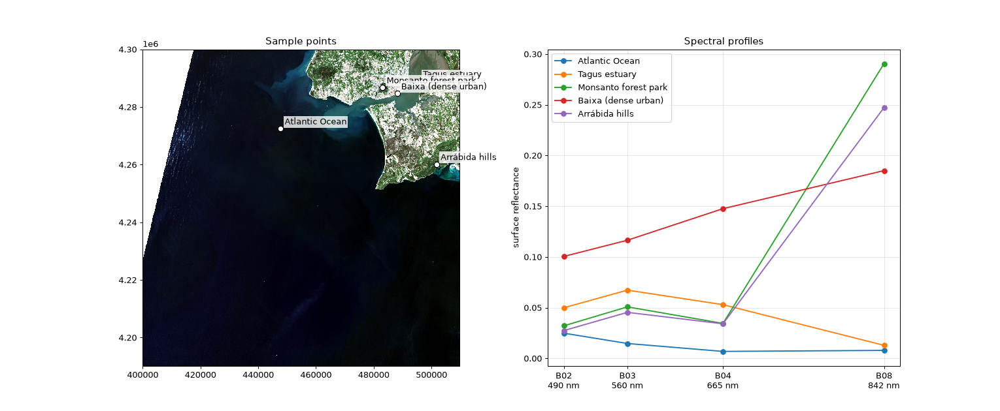

In [88]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1, 1]})
ax1.imshow(as_rgba(stretch(rgb_raw)), extent=extent)
ax1.scatter(xs, ys, c="white", edgecolor="k", s=45, zorder=3)
for name, x, y in zip(POINTS, xs, ys):
    ax1.annotate(
    name, (x, y), xytext=(5, 5), textcoords="offset points",
    color="black", fontsize=10,
    bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.8),
)
ax1.set_title("Sample points")

wl = [S2[b][1] for b in refl.columns]
for name, row in refl.iterrows():
    ax2.plot(wl, row.values, marker="o", label=name)
ax2.set_xticks(wl, [f"{b}\n{w} nm" for b, w in zip(refl.columns, wl)])
ax2.set(ylabel="surface reflectance", title="Spectral profiles")
ax2.grid(alpha=0.3); ax2.legend();

In [100]:
plt.close()

## 4. Histogram of B08 (NIR)
ArcGIS: *Create Chart → Histogram* on B08. Water absorbs NIR almost completely, while vegetation and most land
surfaces reflect it strongly, so this one band already separates the scene into groups. The upper axis shows
reflectance. The dotted line is DN 1000, i.e. zero reflectance.

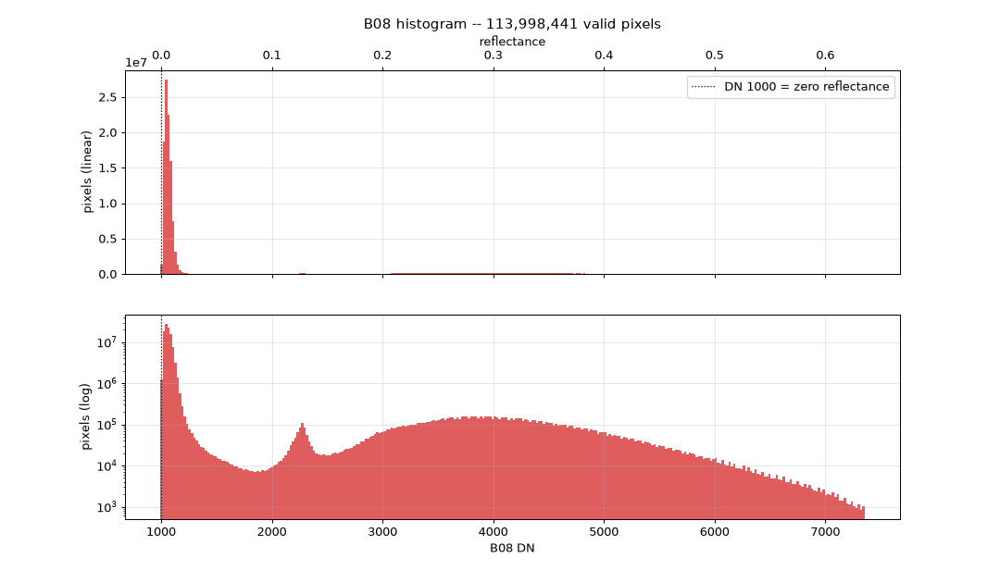

In [101]:
with rasterio.open(bands["B08"]) as src:
    nir_dn = src.read(1)
valid_dn = nir_dn[nir_dn != NODATA]
lo, hi = np.percentile(valid_dn[::97], [0.01, 99.99])
counts, edges = np.histogram(valid_dn, bins=300, range=(lo, hi))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, scale in zip(axes, ("linear", "log")):
    ax.stairs(counts, edges, fill=True, color="tab:red", alpha=0.75)
    ax.axvline(-BOA_ADD_OFFSET, color="k", ls=":", lw=1, label="DN 1000 = zero reflectance")
    ax.set(ylabel=f"pixels ({scale})", yscale=scale)
    ax.grid(alpha=0.3)
axes[0].set_title(f"B08 histogram -- {valid_dn.size:,} valid pixels")
axes[0].secondary_xaxis("top", functions=(lambda d: (d + BOA_ADD_OFFSET) / QUANT,
                                          lambda r: r * QUANT - BOA_ADD_OFFSET)).set_xlabel("reflectance")
axes[0].legend(); axes[1].set_xlabel("B08 DN")
del valid_dn

Test your reading of the histogram: set `CLUSTER` to the DN range of one group and see where those pixels are.

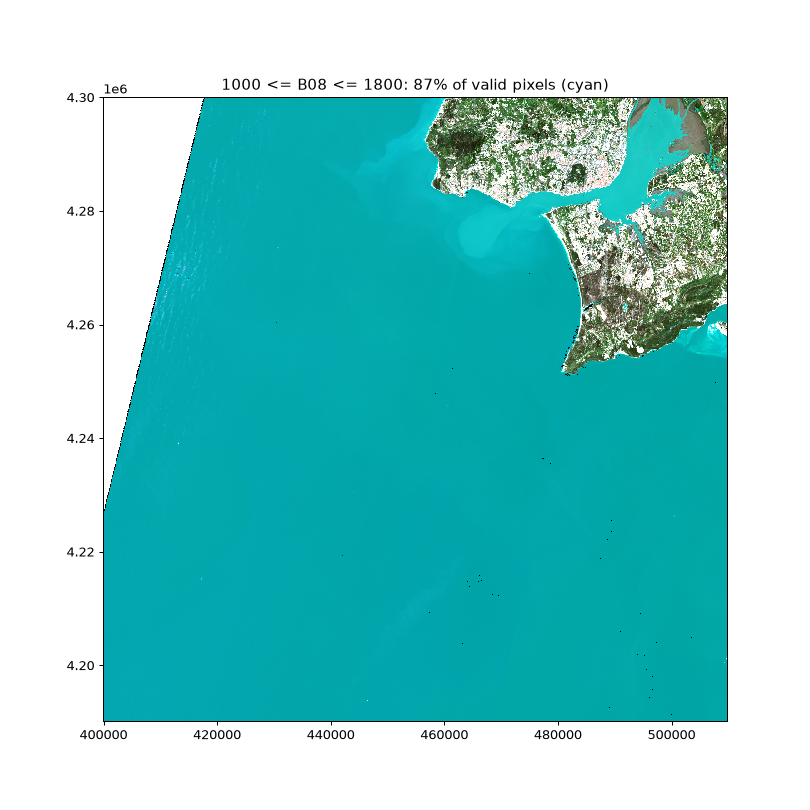

In [102]:
CLUSTER = (1000, 1800)        # DN range of one histogram cluster -- edit
sel = (nir_dn >= CLUSTER[0]) & (nir_dn <= CLUSTER[1])
valid_frac = sel.sum() / np.count_nonzero(nir_dn != NODATA)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(as_rgba(stretch(rgb_raw)), extent=extent)
show(np.ma.masked_array(sel.view(np.uint8), ~sel), plotting_extent(nir_dn, TRANSFORM), ax=ax,
     colorbar=False, cmap=ListedColormap(["cyan"]), alpha=0.65,
     title=f"{CLUSTER[0]} <= B08 <= {CLUSTER[1]}: {valid_frac:.0%} of valid pixels (cyan)")
del sel, nir_dn

**Question 3.** Can you identify groups of similar values in the B08 histogram? Which land-cover types are they?

*Your answer:*

## 5. Composite bands
ArcGIS: *Imagery → Composite* with the layers ordered B02 → B08. Here: stack the four arrays in that order, so
Band_1 = B02, Band_2 = B03, Band_3 = B04, Band_4 = B08, exactly as in ArcGIS. Bands can only be stacked if they share
the same grid (CRS, transform, shape), so that gets checked first.

In [108]:
ORDER = ["B02", "B03", "B04", "B08"]          # -> Band_1 .. Band_4
with rasterio.open(bands[ORDER[0]]) as ref:
    grid = dict(crs=ref.crs, transform=ref.transform, shape=ref.shape)

stack = np.empty((len(ORDER), *grid["shape"]), dtype="uint16")
for i, b in enumerate(ORDER):
    with rasterio.open(bands[b]) as src:
        assert (src.crs, src.transform, src.shape) == (grid["crs"], grid["transform"], grid["shape"]), \
            f"{b} is on a different grid"
        src.read(1, out=stack[i])
print(stack.shape, stack.dtype, f"-- {stack.nbytes / 1e6:,.0f} MB in memory")

(4, 10980, 10980) uint16 -- 964 MB in memory


## 6. Export: uncompressed vs. LZW + pyramids

**GeoTIFF.** A GeoTIFF is an ordinary TIFF plus GeoKeys that tie the pixel grid to the Earth: a CRS and an affine
transform (origin and pixel size). Optional tags sit on top: nodata value, band names, statistics, colour tables.
`src.profile` and `src.tags()` show them.

**Pyramids (overviews)** are pre-computed copies at ½, ¼, ⅛ … resolution, so a zoomed-out view reads a small overview
instead of all 120 M pixels per band. ArcGIS writes them to a side-car `Composite.tif.ovr`; here they are stored inside
the file, and GDAL treats both the same way. JPEG 2000 has the equivalent built into the codec (resolution levels),
which is why previews of the input `.jp2` files are already fast.

**Compression.** Lossless codecs (LZW, DEFLATE, ZSTD) return exactly the original values. Lossy ones (JPEG, WebP,
lossy JPEG 2000) throw information away to shrink files further: fine for display copies, wrong for data you will
compute on. `predictor=2` stores differences between neighbouring pixels, which LZW compresses much better for
integer imagery. The LZW file below carries its pyramids inside, which adds about a third
(¼ + ¹⁄₁₆ + … ≈ ⅓ of the full-resolution data). ArcGIS's ~637 MB is the `.tif` alone, with the pyramids in the `.ovr`.

In [109]:
DESCR = [f"{b} {S2[b][0]}" for b in ORDER]

t = time.perf_counter()
comp_raw = write_tif(OUT_DIR / "Composite_uncompressed.tif", stack, grid["crs"], grid["transform"], NODATA,
                     compress=None, overviews=False, descriptions=DESCR)
print(f"uncompressed, no pyramids : {time.perf_counter() - t:5.1f} s to write")

t = time.perf_counter()
comp = write_tif(OUT_DIR / "Composite.tif", stack, grid["crs"], grid["transform"], NODATA, descriptions=DESCR)
print(f"LZW + pyramids            : {time.perf_counter() - t:5.1f} s to write")
del stack

uncompressed, no pyramids :   1.0 s to write
LZW + pyramids            :   5.4 s to write


ArcGIS's "rendering speed" corresponds to fetching a screen-sized view of the whole image. That is timed below for both
files (best of three runs).

In [110]:
def best_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return min(times)

rows = []
for p in (comp_raw, comp):
    with rasterio.open(p) as src:
        rows.append({
            "file": p.name,
            "size_MB": round(p.stat().st_size / 1e6),
            "compression": src.compression.value if src.compression else "none",
            "overview levels": src.overviews(1),
            "screen-size read (s)": round(best_time(lambda: read_preview(p, [3, 2, 1])), 2),
        })
pd.DataFrame(rows).set_index("file")

,size_MB,compression,overview levels,screen-size read (s)
file,,,,
Composite_uncompressed.tif,965,none,[],2.11
Composite.tif,761,LZW,"[2, 4, 8, 16, 32, 64]",0.12


In [111]:
with rasterio.open(comp) as src:
    print("profile          :", src.profile)
    print("band descriptions:", src.descriptions)
    print("image structure  :", src.tags(ns="IMAGE_STRUCTURE"))
    print("overview levels  :", src.overviews(1))

comp_raw.unlink()       # as in the lab: delete the uncompressed copy once compared

profile          : {'driver': 'GTiff', 'dtype': 'uint16', 'nodata': 0.0, 'width': 10980, 'height': 10980, 'count': 4, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 29N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-9],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32629"]]'), 'transform': Affine(10.0, 0.0, 399960.0,
       0.0, -10.0, 4300020.0), 'blockxsize': 512, 'blockysize': 512, 'tiled': True, 'compress': 'lzw', 'interleave': 'pixel'}
band descriptions: ('B02 Blue', 'B03 Green', 'B04 Red', 'B08 NIR')
image structure  : {'COMPR

## 7. True colour
Red = Band_3 (B04), Green = Band_2 (B03), Blue = Band_1 (B02). Below, ArcGIS's stretch types side by side. *none*
maps the raw 16-bit range to the screen, which is why that version looks so dark. Over this tile the statistics are
dominated by the Atlantic, so stretches computed on the whole image tend to blow out the land.

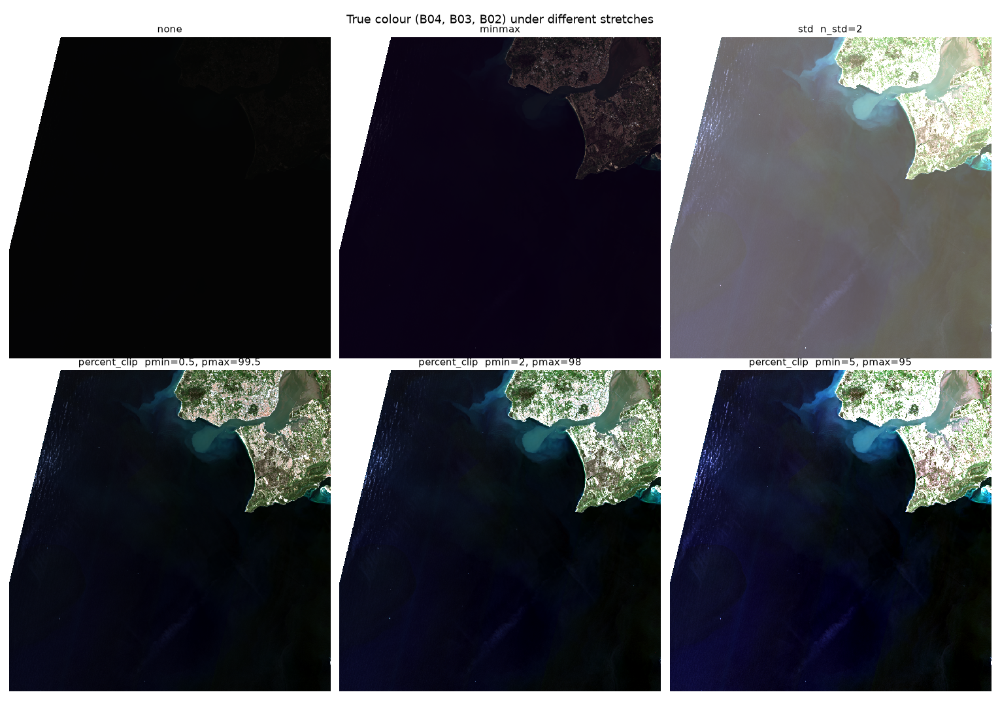

In [112]:
rgb, extent = read_preview(comp, [3, 2, 1])     # served from the overviews just built
options = [("none", {}), ("minmax", {}), ("std", {"n_std": 2}),
           ("percent_clip", {"pmin": 0.5, "pmax": 99.5}), ("percent_clip", {"pmin": 2, "pmax": 98}),
           ("percent_clip", {"pmin": 5, "pmax": 95})]

fig, axes = plt.subplots(2, 3, figsize=(17, 12))
for ax, (method, kw) in zip(axes.flat, options):
    ax.imshow(as_rgba(stretch(rgb, method, **kw)), extent=extent)
    ax.set_title(method + ("  " + ", ".join(f"{k}={v}" for k, v in kw.items()) if kw else ""))
    ax.set_axis_off()
fig.suptitle("True colour (B04, B03, B02) under different stretches", fontsize=14)
plt.tight_layout()

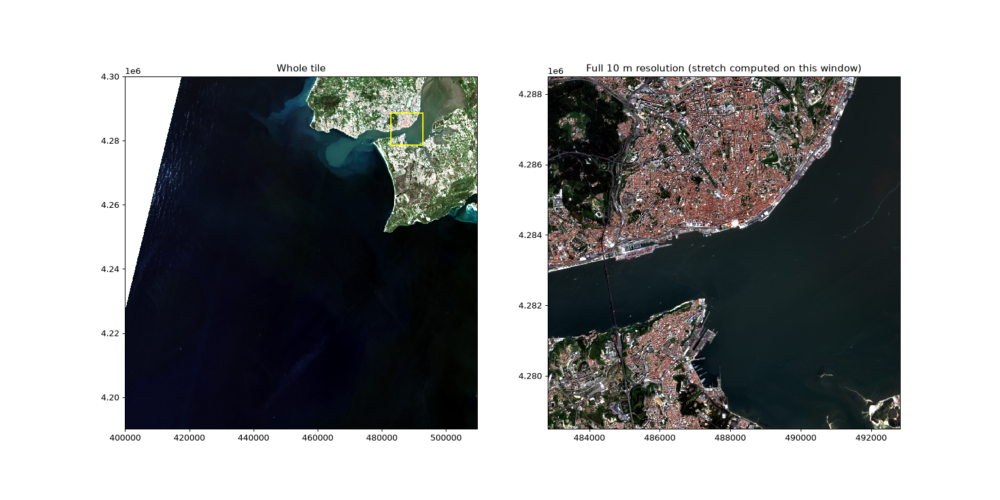

In [113]:
TRUE_COLOUR = dict(method="percent_clip", pmin=1, pmax=99)    # pick your favourite
ZOOM = (-9.14, 38.70, 5000)                                   # lon, lat, half-size (m): Lisbon waterfront

z, zext = read_zoom(comp, [3, 2, 1], *ZOOM)
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
axes[0].imshow(as_rgba(stretch(rgb, **TRUE_COLOUR)), extent=extent)
axes[0].add_patch(plt.Rectangle((zext[0], zext[2]), zext[1] - zext[0], zext[3] - zext[2],
                                fill=False, ec="yellow", lw=1.5))
axes[0].set_title("Whole tile")
axes[1].imshow(as_rgba(stretch(z, **TRUE_COLOUR)), extent=zext)
axes[1].set_title("Full 10 m resolution (stretch computed on this window)");

**Question.** Do the colours look correct?

*Your answer:*

## 8. False colour (NIR)
Red = Band_4 (B08, NIR), Green = Band_3 (B04, Red), Blue = Band_2 (B03, Green). Healthy vegetation reflects NIR
strongly, so it shows up red.

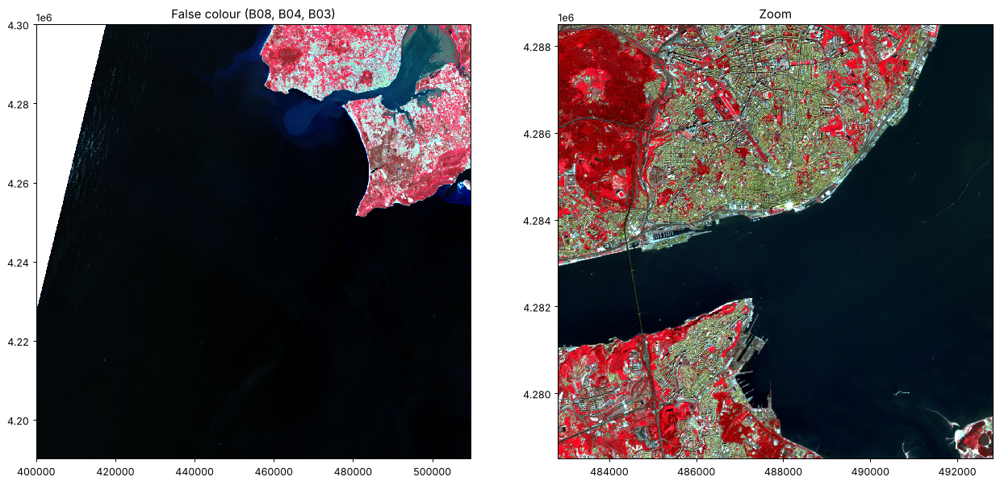

In [17]:
fc, _ = read_preview(comp, [4, 3, 2])
zf, _ = read_zoom(comp, [4, 3, 2], *ZOOM)
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
axes[0].imshow(as_rgba(stretch(fc, **TRUE_COLOUR)), extent=extent)
axes[0].set_title("False colour (B08, B04, B03)")
axes[1].imshow(as_rgba(stretch(zf, **TRUE_COLOUR)), extent=zext)
axes[1].set_title("Zoom");

**Question.** Is the new symbology correct?

*Your answer:*

## Spectral indices

| Index | Formula | Sentinel-2 bands | Used for |
|---|---|---|---|
| NDVI | (NIR − Red) / (NIR + Red) | B08, B04 | vegetation cover and vigour |
| NDWI | (Green − NIR) / (Green + NIR) | B03, B08 | open water (McFeeters) |
| NDBI | (SWIR1 − NIR) / (SWIR1 + NIR) | B11, B08 | built-up and bare surfaces |
| NBR  | (NIR − SWIR2) / (NIR + SWIR2) | B08, B12 | burned areas, burn severity |
| EVI  | 2.5 (NIR − Red) / (NIR + 6 Red − 7.5 Blue + 1) | B08, B04, B02 | vegetation; saturates less in dense canopy |

The lab leaves the SWIR band open for NDBI and NBR; B11 and B12 respectively are the usual choices. EVI's constants
assume reflectance in 0–1, so EVI is only meaningful after the DN → reflectance conversion.

In [18]:
def ndvi(nir, red):
    return nd(nir, red)

def ndwi(green, nir):
    return nd(green, nir)

def ndbi(swir1, nir):
    return nd(swir1, nir)

def nbr(nir, swir2):
    return nd(nir, swir2)

def evi(nir, red, blue):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.clip(2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1), -1, 1)

def comp_band(i):
    '''Band i of Composite.tif as reflectance (1 = B02, 2 = B03, 3 = B04, 4 = B08).'''
    with rasterio.open(comp) as src:
        return to_reflectance(src.read(i))

### NDVI
ArcGIS: *Imagery → Indices → NDVI* with NIR = Band_4, Red = Band_3.

NDVI   min -1.000   p1 -0.609   median -0.115   p99 0.832   max 1.000
clipped at +-1 (negative reflectance): 0.05% of valid pixels


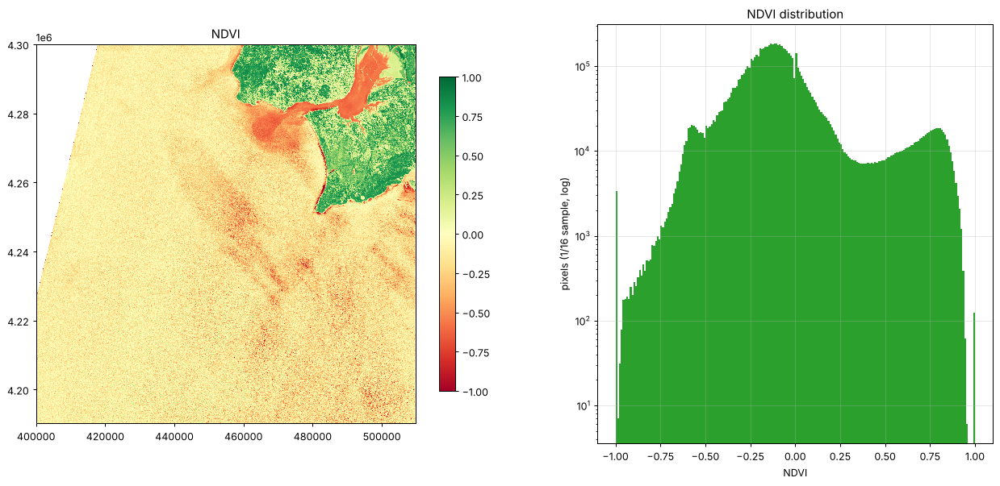

In [19]:
ndvi_arr = ndvi(nir=comp_band(4), red=comp_band(3))
ext = plotting_extent(ndvi_arr, grid["transform"])

v = ndvi_arr[::4, ::4]
v = v[np.isfinite(v)]
print(f"NDVI   min {v.min():.3f}   p1 {np.percentile(v, 1):.3f}   median {np.median(v):.3f}   "
      f"p99 {np.percentile(v, 99):.3f}   max {v.max():.3f}")
print(f"clipped at +-1 (negative reflectance): {np.mean(np.abs(v) == 1):.2%} of valid pixels")

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1.2, 1]})
show(ndvi_arr, ext, ax=axes[0], cmap="RdYlGn", vmin=-1, vmax=1, title="NDVI")
axes[1].hist(v, bins=200, range=(-1, 1), color="tab:green")
axes[1].set(xlabel="NDVI", ylabel="pixels (1/16 sample, log)", yscale="log", title="NDVI distribution")
axes[1].grid(alpha=0.3)

Multiplying by 10 000 and storing as int16 keeps four decimals at half the size of float32. This is the scaling the lab
refers to.

In [20]:
ndvi_i16 = np.where(np.isfinite(ndvi_arr), np.round(ndvi_arr * 10_000), -32768).astype("int16")
p = write_tif(OUT_DIR / "NDVI.tif", ndvi_i16, grid["crs"], grid["transform"], nodata=-32768,
              descriptions=["NDVI x 10000"])
print(f"{p.name}: {p.stat().st_size / 1e6:.0f} MB")
del ndvi_i16

NDVI.tif: 350 MB


### Why the offset matters
The same NDVI computed the ArcGIS way (raw DNs) and on reflectance, every 4th pixel:

pixels with reflectance-NDVI > 0.6: raw-DN NDVI averages 0.481 instead of 0.741


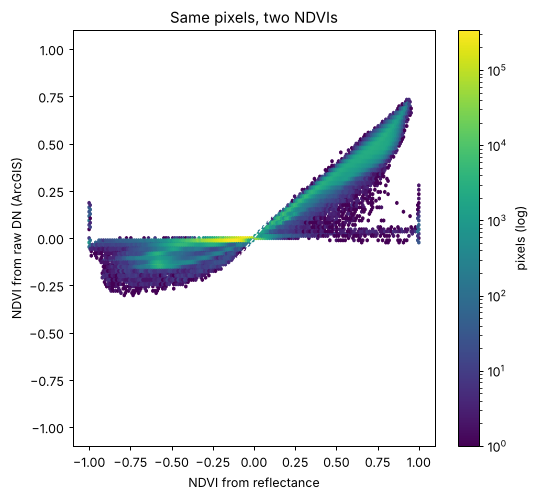

In [21]:
L2A_OFFSET = -1000
with rasterio.open(comp) as src:
    f = 4
    red_dn, nir_dn = src.read([3, 4], out_shape=(2, src.height // f, src.width // f),
                              resampling=Resampling.nearest).astype("float32")
ok = (red_dn > 0) & (nir_dn > 0)
ndvi_dn = nd(nir_dn, red_dn)[ok]                                   # Imagery > Indices > NDVI
ndvi_rf = nd(nir_dn + L2A_OFFSET, red_dn + L2A_OFFSET)[ok]         # offset removed

veg = ndvi_rf > 0.6
print(f"pixels with reflectance-NDVI > 0.6: raw-DN NDVI averages {ndvi_dn[veg].mean():.3f} "
      f"instead of {ndvi_rf[veg].mean():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(ndvi_rf, ndvi_dn, gridsize=150, bins="log", extent=(-1, 1, -1, 1), cmap="viridis")
ax.plot([-1, 1], [-1, 1], "w--", lw=1)
ax.set(xlabel="NDVI from reflectance", ylabel="NDVI from raw DN (ArcGIS)", title="Same pixels, two NDVIs")
plt.colorbar(hb, ax=ax, label="pixels (log)")
del red_dn, nir_dn, ndvi_dn, ndvi_rf

### NDWI
ArcGIS: *Raster Functions → Band Arithmetic* with `(B2 - B4) / (B2 + B4)`, i.e. Band_2 = B03 (Green) and
Band_4 = B08 (NIR). The diverging colour map plays the role of the inverted "Bathymetry #2" scheme: water blue, land red.

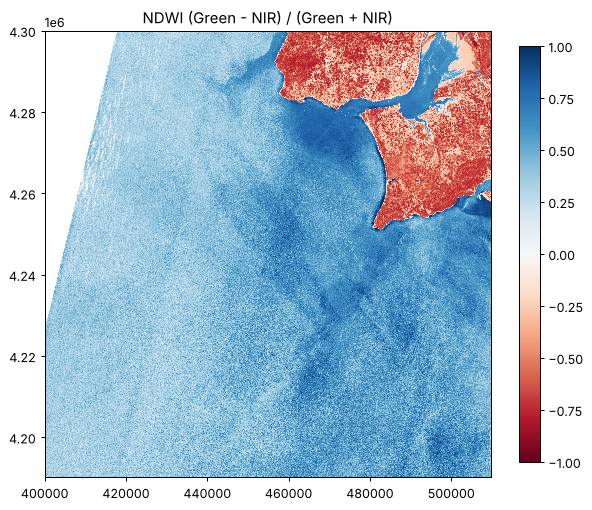

In [22]:
ndwi_arr = ndwi(green=comp_band(2), nir=comp_band(4))
show(ndwi_arr, ext, cmap="RdBu", vmin=-1, vmax=1, title="NDWI (Green - NIR) / (Green + NIR)")

ndwi_i16 = np.where(np.isfinite(ndwi_arr), np.round(ndwi_arr * 10_000), -32768).astype("int16")
write_tif(OUT_DIR / "NDWI.tif", ndwi_i16, grid["crs"], grid["transform"], nodata=-32768,
          descriptions=["NDWI x 10000"])
del ndwi_i16

**Question.** What is the range of NDVI values?

*Your answer:*

In [23]:
del ndvi_arr, ndwi_arr      # free ~1 GB before the exercise

# Exercise — burned areas from the 23 August 2025 image

The `Exercise` folder holds tile T29TNE (central Portugal) with B02, B03, B04, B08 at 10 m and B12 (SWIR 2) at 20 m,
plus the official ICNF 2025 burned-area perimeters (`burned_areas_2025.shp`).

1. Build a multiband composite, harmonising the 20 m SWIR band with the 10 m bands.
2. Compute NDVI and NBR. Which one identifies burned areas better?
3. Pick a threshold and make a binary burned/unburned map.
4. Validate it against the ICNF perimeters.

In [24]:
ex = find_bands(EX_DIR)
for b, tiles in ex.items():
    for tile, p in tiles.items():
        with rasterio.open(p) as src:
            print(f"{b:4} {tile}  {src.res[0]:>3.0f} m  {src.width:>5} x {src.height:<5}  {src.crs}  {p.name}")

SWIR2 = "B12" if "B12" in ex else "B11"          # NBR is normally computed with B12
stamp = re.search(r"(\d{8}T\d{6})", next(iter(ex["B08"].values())).name).group(1)
EX_IMAGE_TIME = pd.to_datetime(stamp, format="%Y%m%dT%H%M%S").tz_localize("UTC")
print("\nsensing time:", EX_IMAGE_TIME, "=", EX_IMAGE_TIME.tz_convert("Europe/Lisbon"), "Lisbon")

B02  T29TNE   10 m  10980 x 10980  EPSG:32629  T29TNE_20250823T112131_B02_10m.jp2
B03  T29TNE   10 m  10980 x 10980  EPSG:32629  T29TNE_20250823T112131_B03_10m.jp2
B04  T29TNE   10 m  10980 x 10980  EPSG:32629  T29TNE_20250823T112131_B04_10m.jp2
B08  T29TNE   10 m  10980 x 10980  EPSG:32629  T29TNE_20250823T112131_B08_10m.jp2
B12  T29TNE   20 m   5490 x 5490   EPSG:32629  T29TNE_20250823T112131_B12_20m.jp2

sensing time: 2025-08-23 11:21:31+00:00 = 2025-08-23 12:21:31+01:00 Lisbon


### E1. Composite with the SWIR band harmonised
The 10 m B08 grid is the target. B12 is resampled onto it with `rasterio.warp.reproject`, which does the same job as
ArcGIS's *Resample* tool or the cell-size environment setting. Nearest neighbour turns each 20 m pixel into a 2×2
block of identical values and invents nothing; bilinear gives a smoother band. If the folder held several tiles,
`load_band` would mosaic them first.

In [25]:
REF_BAND = "B08"
RESAMPLING = Resampling.nearest

def load_band(band, grid=None, resampling=RESAMPLING):
    '''Mosaic every tile of `band` (one tile -> plain read) and optionally resample it onto `grid`.'''
    srcs = [rasterio.open(p) for p in ex[band].values()]
    try:
        crs = srcs[0].crs
        assert all(s.crs == crs for s in srcs), "tiles are in different CRSs -- reproject them first"
        arr, transform = merge(srcs, nodata=NODATA)
    finally:
        for s in srcs:
            s.close()
    arr = arr[0]
    if grid is None or (transform == grid["transform"] and arr.shape == grid["shape"]):
        return arr, crs, transform
    out = np.zeros(grid["shape"], dtype=arr.dtype)
    reproject(arr, out, src_transform=transform, src_crs=crs, src_nodata=NODATA,
              dst_transform=grid["transform"], dst_crs=grid["crs"], dst_nodata=NODATA, resampling=resampling)
    return out, grid["crs"], grid["transform"]


ref_arr, ex_crs, ex_transform = load_band(REF_BAND)
ex_grid = dict(crs=ex_crs, transform=ex_transform, shape=ref_arr.shape)
EX_ORDER = [b for b in ("B02", "B03", "B04", "B08", "B8A", "B11", "B12") if b in ex]

ex_stack = np.empty((len(EX_ORDER), *ex_grid["shape"]), dtype="uint16")
for i, b in enumerate(EX_ORDER):
    ex_stack[i] = ref_arr if b == REF_BAND else load_band(b, ex_grid)[0]
del ref_arr

ex_comp = write_tif(OUT_DIR / "Exercise_composite.tif", ex_stack, ex_crs, ex_transform, NODATA,
                    descriptions=[f"{b} {S2[b][0]}" for b in EX_ORDER])
EXB = {b: i + 1 for i, b in enumerate(EX_ORDER)}          # band name -> band number in the composite

# sanity check: with nearest, every 10 m pixel equals the 20 m pixel it falls in
b12_native, _, _ = load_band(SWIR2)
assert np.array_equal(ex_stack[EXB[SWIR2] - 1][::2, ::2], b12_native)
print(f"{ex_comp.name}: bands {EX_ORDER}, {ex_grid['shape'][1]} x {ex_grid['shape'][0]} px at 10 m, "
      f"{ex_comp.stat().st_size / 1e6:.0f} MB")
del ex_stack, b12_native

Exercise_composite.tif: bands ['B02', 'B03', 'B04', 'B08', 'B12'], 10980 x 10980 px at 10 m, 1312 MB


#### Reference data and its timing
The ICNF layer covers all of 2025, while the image is one moment, so each perimeter is labelled by its status when
the image was taken. Fires that started afterwards can't appear in the image. One still burning at acquisition was
only partly burned at that point, though its final perimeter is in the layer. ICNF times are taken as Lisbon local time.

In [26]:
import geopandas as gpd
from shapely.geometry import box

fires = gpd.read_file(EX_DIR / "burned_areas_2025.shp")
print(fires.crs, "|", len(fires), "perimeters in the file")
for col in ("DH_Inicio", "DH_Fim"):
    fires[col] = (pd.to_datetime(fires[col], format="%Y/%m/%d %H:%M:%S.%f")
                    .dt.tz_localize("Europe/Lisbon", ambiguous="NaT", nonexistent="shift_forward"))

fires = fires.to_crs(ex_crs)
footprint = box(*array_bounds(*ex_grid["shape"], ex_transform))
fires = fires[fires.intersects(footprint)].copy()
fires["ha_in_image"] = fires.intersection(footprint).area / 1e4
fires["status"] = np.select([fires["DH_Inicio"] > EX_IMAGE_TIME, fires["DH_Fim"] > EX_IMAGE_TIME],
                            ["started after image", "burning at image time"], "out before image")

EXCLUDE_LATER_FIRES = True       # fires that started after the image cannot be seen in it
ref_fires = fires[fires["status"] != "started after image"] if EXCLUDE_LATER_FIRES else fires

display(fires.groupby("status")["ha_in_image"].agg(perimeters="count", hectares="sum").round(0))
display(fires.sort_values("ha_in_image", ascending=False)
             [["DH_Inicio", "DH_Fim", "PI_Conc", "PI_Local", "ha_in_image", "status"]].head(8)
             .style.format({"ha_in_image": "{:,.0f}"}))

EPSG:4326 | 76 perimeters in the file


,perimeters,hectares
status,,
burning at image time,1,34526.0
out before image,35,4604.0
started after image,12,3139.0


,DH_Inicio,DH_Fim,PI_Conc,PI_Local,ha_in_image,status
75,2025-08-13 00:00:00+01:00,2025-08-25 00:00:00+01:00,Arganil,Piódão (Outeiro da Eira Cerquinhal),"34,526",burning at image time
18,2025-08-14 13:46:00+01:00,2025-08-19 09:00:00+01:00,Lousã,Candal,"3,325",out before image
37,2025-09-06 10:29:00+01:00,2025-09-07 08:00:00+01:00,Seia,Quinta das Minas,"1,860",started after image
44,2025-08-10 15:02:00+01:00,2025-08-13 09:11:00+01:00,Covilhã,Pereiro - Covilhã (Pereiro),721,out before image
36,2025-09-19 13:25:00+01:00,2025-09-25 20:55:00+01:00,Oliveira do Hospital,Tapada,625,started after image
28,2025-08-23 15:21:00+01:00,2025-08-23 18:40:00+01:00,Pedrógão Grande,Casal da Marinha,286,started after image
27,2025-08-23 14:27:00+01:00,2025-08-24 17:30:00+01:00,Pedrógão Grande,Fábrica de Papel,270,started after image
34,2025-07-30 09:07:00+01:00,2025-07-30 18:28:00+01:00,Seia,Quinta dos Covais,214,out before image


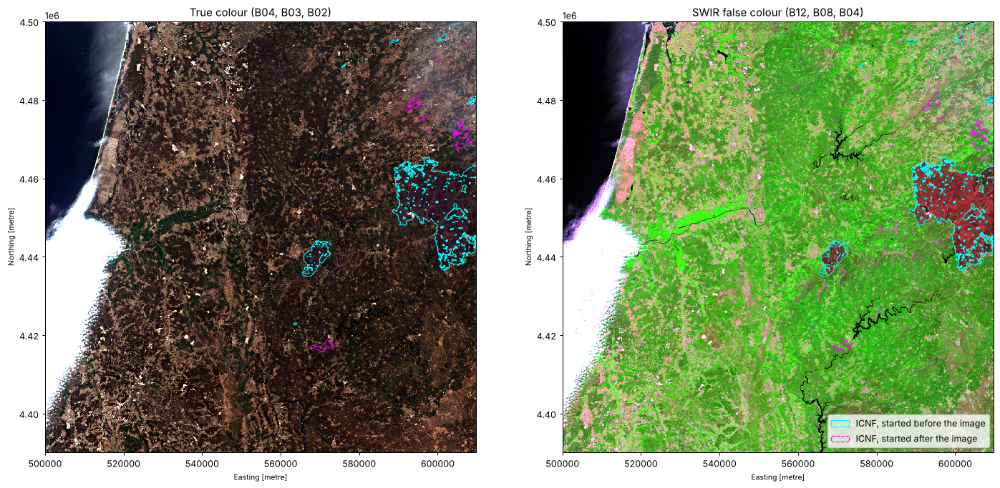

In [27]:
views = {"True colour (B04, B03, B02)": ["B04", "B03", "B02"],
         f"SWIR false colour ({SWIR2}, B08, B04)": [SWIR2, "B08", "B04"]}
later = fires[fires["status"] == "started after image"]

fig, axes = plt.subplots(1, 2, figsize=(19, 9.5))
for ax, (title, bnames) in zip(axes, views.items()):
    img, ex_extent = read_preview(ex_comp, [EXB[b] for b in bnames])
    ax.imshow(as_rgba(stretch(img, pmin=0.5, pmax=95)), extent=ex_extent)   # low pmax: clouds/smoke are very bright
    ref_fires.boundary.plot(ax=ax, color="cyan", lw=0.7)
    if len(later):
        later.boundary.plot(ax=ax, color="magenta", lw=0.7, ls="--")
    ax.set_xlim(ex_extent[:2]); ax.set_ylim(ex_extent[2:]); ax.set_title(title)
axes[1].legend(handles=[Patch(ec="cyan", fc="none", label="ICNF, started before the image"),
                        Patch(ec="magenta", fc="none", ls="--", label="ICNF, started after the image")],
               loc="lower right");

### E2. NDVI and NBR

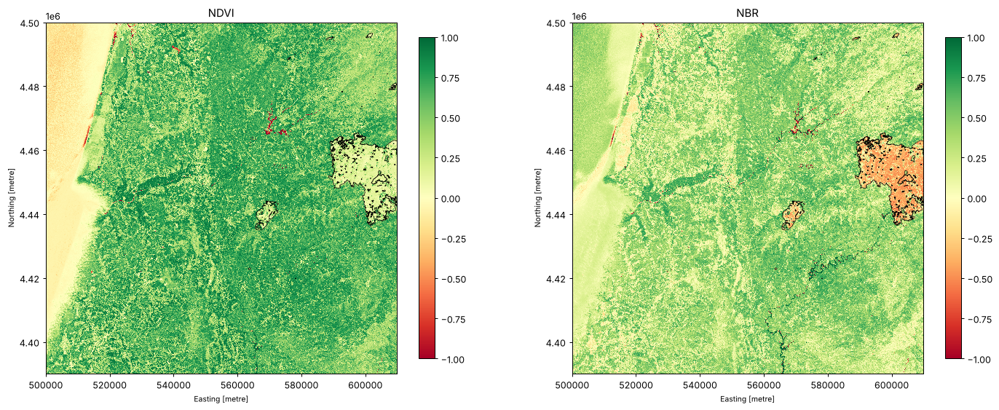

In [28]:
def exb(band):
    '''One band of the exercise composite as reflectance.'''
    with rasterio.open(ex_comp) as src:
        return to_reflectance(src.read(EXB[band]))

nir = exb("B08")
ex_ndvi = ndvi(nir, exb("B04"))
ex_nbr = nbr(nir, exb(SWIR2))
del nir
IDX = {"NDVI": ex_ndvi, "NBR": ex_nbr}
ex_ext = plotting_extent(ex_ndvi, ex_transform)

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5))
for ax, (k, a) in zip(axes, IDX.items()):
    show(a, ex_ext, ax=ax, cmap="RdYlGn", vmin=-1, vmax=1, title=k)
    ref_fires.boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_xlim(ex_ext[:2]); ax.set_ylim(ex_ext[2:])

#### Water and cloud masks (optional, not in the ArcGIS lab)
Water and clouds also have low NDVI, and water can have low NBR. Both are well outside any burn scar, so a quick
mask helps either index: NDWI > 0 for water (the index from the main lab), and a crude brightness test on B02 for
clouds and thick smoke. Masked pixels are mapped as *unburned* rather than dropped, so the validation still covers
every pixel. Set `APPLY_MASKS = False` to compare the two indices on their own.

water 10.8%   cloud/smoke 6.4%   masked 13.1% of the image


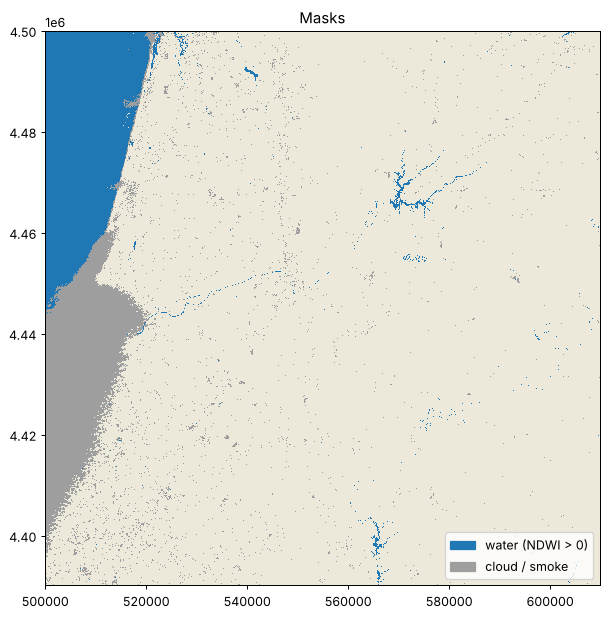

In [29]:
APPLY_MASKS = True
CLOUD_B02 = 0.15          # blue reflectance above which a pixel is treated as cloud / thick smoke

water = ndwi(exb("B03"), exb("B08")) > 0
cloud = exb("B02") > CLOUD_B02
mask = (water | cloud) if APPLY_MASKS else np.zeros(water.shape, bool)
print(f"water {water.mean():.1%}   cloud/smoke {cloud.mean():.1%}   masked {mask.mean():.1%} of the image")

cat = np.zeros(water.shape, np.uint8)
cat[water] = 1
cat[cloud] = 2
mask_cmap = ListedColormap(["#ece8da", "#1f77b4", "#9e9e9e"])
ax = show(cat, ex_ext, cmap=mask_cmap, vmin=0, vmax=2, colorbar=False, title="Masks")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(mask_cmap.colors[1:], ["water (NDWI > 0)", "cloud / smoke"])],
          loc="lower right")
del cat, water, cloud

### E3. Threshold → binary burned / unburned map
Both indices drop over burned ground, so *burned = index < threshold*. Otsu's method picks the threshold that best
separates a histogram into classes without using any reference data. With two classes it usually lands between
vegetated and non-vegetated land, which is the wrong split here (dotted line). Splitting into four classes and taking
the lowest boundary (red) isolates the darkest values. That gives a starting point. Check the maps and set
`THRESHOLDS` yourself.

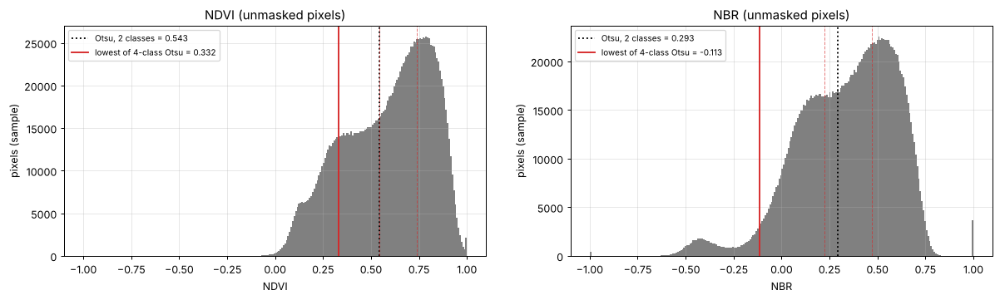

In [30]:
from skimage.filters import threshold_otsu, threshold_multiotsu

rng = np.random.default_rng(42)

def sample(arr, n=2_000_000, exclude=None):
    '''Random sample of the finite values of arr, optionally skipping pixels where `exclude` is True.'''
    pos = rng.integers(0, arr.size, n)
    if exclude is not None:
        pos = pos[~exclude.ravel()[pos]]
    v = arr.ravel()[pos]
    return v[np.isfinite(v)]

OTSU_CLASSES = 4
otsu2, otsu = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (k, a) in zip(axes, IDX.items()):
    v = sample(a, exclude=mask)
    otsu2[k] = float(threshold_otsu(v))
    multi = threshold_multiotsu(v, classes=OTSU_CLASSES)
    otsu[k] = float(multi[0])
    ax.hist(v, bins=250, range=(-1, 1), color="grey")
    ax.axvline(otsu2[k], color="k", ls=":", label=f"Otsu, 2 classes = {otsu2[k]:.3f}")
    for t in multi[1:]:
        ax.axvline(t, color="tab:red", ls="--", lw=0.8, alpha=0.6)
    ax.axvline(otsu[k], color="tab:red", label=f"lowest of {OTSU_CLASSES}-class Otsu = {otsu[k]:.3f}")
    ax.set(title=f"{k} (unmasked pixels)", xlabel=k, ylabel="pixels (sample)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

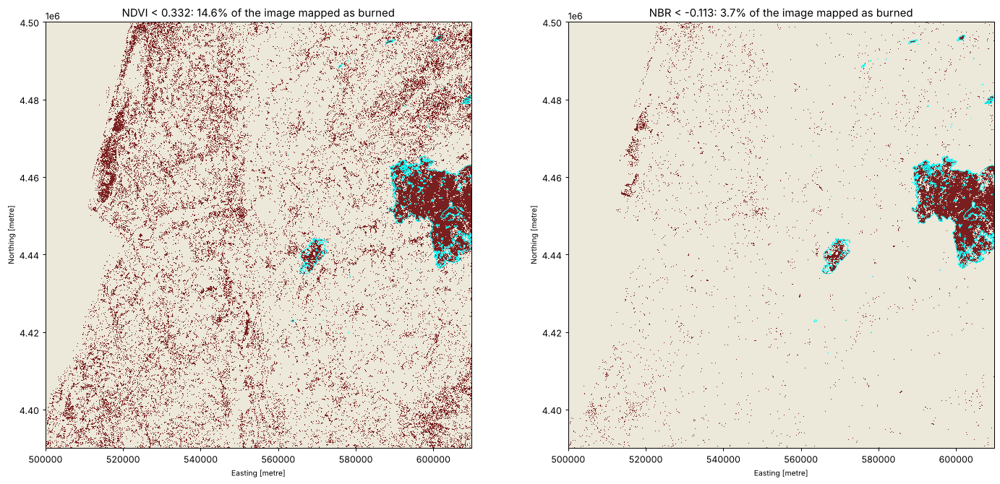

In [31]:
THRESHOLDS = {"NDVI": otsu["NDVI"], "NBR": otsu["NBR"]}     # <-- set your own; burned = index < threshold

valid = np.isfinite(ex_ndvi) & np.isfinite(ex_nbr)
burned = {k: (a < THRESHOLDS[k]) & ~mask for k, a in IDX.items()}
binary_cmap = ListedColormap(["#ece8da", "#7a1f1f"])

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5))
for ax, (k, m) in zip(axes, burned.items()):
    show(np.ma.masked_array(m.view(np.uint8), ~valid), ex_ext, ax=ax, colorbar=False,
         cmap=binary_cmap, vmin=0, vmax=1,
         title=f"{k} < {THRESHOLDS[k]:.3f}: {m[valid].mean():.1%} of the image mapped as burned")
    ref_fires.boundary.plot(ax=ax, color="cyan", lw=0.6)
    ax.set_xlim(ex_ext[:2]); ax.set_ylim(ex_ext[2:])
    write_tif(OUT_DIR / f"burned_{k}.tif", np.where(valid, m, 255).astype("uint8"), ex_crs, ex_transform,
              nodata=255, ov_resampling=Resampling.nearest,
              descriptions=[f"1 = burned ({k} < {THRESHOLDS[k]:.3f}), 0 = unburned"])

### E4. Validation against ICNF
The perimeters are rasterised onto the 10 m grid and compared pixel by pixel. Burned land is a small fraction of the
tile, so overall accuracy and kappa are inflated by the many easy *unburned* pixels. User's/producer's accuracy
(precision/recall), F1 and IoU are the informative numbers for a rare class. Masked pixels count as mapped *unburned*.

In [32]:
from rasterio.features import rasterize

ref_mask = rasterize(((g, 1) for g in ref_fires.geometry), out_shape=ex_grid["shape"],
                     transform=ex_transform, fill=0, dtype="uint8").astype(bool)
PX_HA = abs(ex_transform.a * ex_transform.e) / 1e4

def accuracy(pred, ref, valid):
    p, r = pred[valid], ref[valid]
    tp = int(np.count_nonzero(p & r));  fp = int(np.count_nonzero(p & ~r))
    fn = int(np.count_nonzero(~p & r)); tn = p.size - tp - fp - fn
    n = p.size
    oa = (tp + tn) / n
    pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n**2
    div = lambda a, b: a / b if b else np.nan
    return pd.Series({
        "mapped burned (ha)": (tp + fp) * PX_HA, "ICNF burned (ha)": (tp + fn) * PX_HA,
        "TP (ha)": tp * PX_HA, "FP (ha)": fp * PX_HA, "FN (ha)": fn * PX_HA,
        "user's accuracy / precision": div(tp, tp + fp), "producer's accuracy / recall": div(tp, tp + fn),
        "commission error": div(fp, tp + fp), "omission error": div(fn, tp + fn),
        "F1": div(2 * tp, 2 * tp + fp + fn), "IoU": div(tp, tp + fp + fn),
        "overall accuracy": oa, "kappa": div(oa - pe, 1 - pe),
    })

scores = pd.DataFrame({f"{k} < {THRESHOLDS[k]:.3f}": accuracy(m, ref_mask, valid) for k, m in burned.items()})
scores.style.format("{:,.0f}", subset=pd.IndexSlice[scores.index[:5], :]) \
            .format("{:.3f}", subset=pd.IndexSlice[scores.index[5:], :])

,NDVI < 0.332,NBR < -0.113
mapped burned (ha),"176,227","44,420"
ICNF burned (ha),"39,130","39,130"
TP (ha),"32,524","30,947"
FP (ha),"143,703","13,474"
FN (ha),"6,606","8,184"
user's accuracy / precision,0.185,0.697
producer's accuracy / recall,0.831,0.791
commission error,0.815,0.303
omission error,0.169,0.209
F1,0.302,0.741


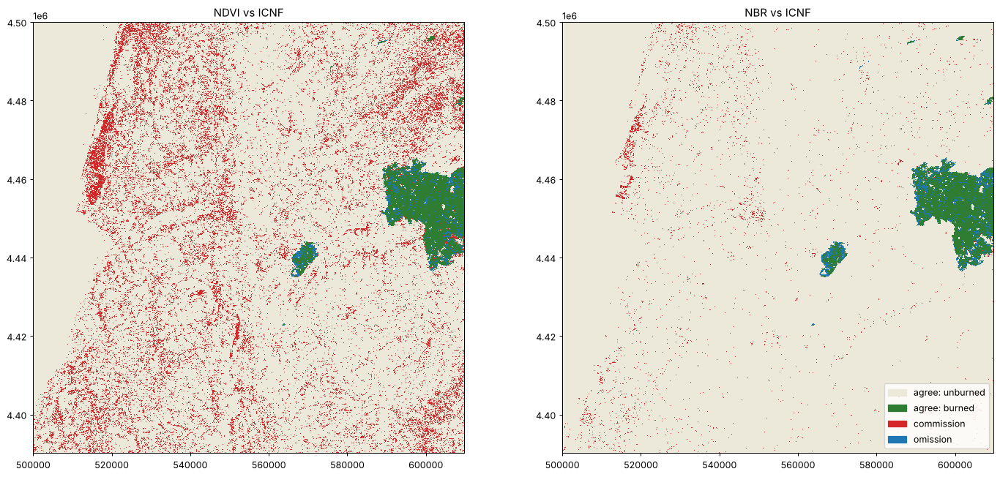

In [33]:
err_cmap = ListedColormap(["#ece8da", "#2e7d32", "#d62728", "#1f77b4"])
fig, axes = plt.subplots(1, 2, figsize=(19, 8.5))
for ax, (k, m) in zip(axes, burned.items()):
    err = np.zeros(m.shape, np.uint8)
    err[m & ref_mask] = 1          # correctly mapped burned
    err[m & ~ref_mask] = 2         # commission (false alarm)
    err[~m & ref_mask] = 3         # omission (missed)
    show(np.ma.masked_array(err, ~valid), ex_ext, ax=ax, colorbar=False, cmap=err_cmap, vmin=0, vmax=3,
         title=f"{k} vs ICNF")
    del err
axes[1].legend(handles=[Patch(color=c, label=l) for c, l in
                        zip(err_cmap.colors, ["agree: unburned", "agree: burned", "commission", "omission"])],
               loc="lower right");

**Threshold-free comparison.** How well does each index separate pixels inside the ICNF perimeters from those outside,
whatever the threshold? The ROC AUC is the probability that a random burned pixel has a lower index value than a
random unburned one (0.5 = no separation, 1 = perfect). It is computed over all valid pixels and over the unmasked
ones; the histograms show the unmasked pixels.

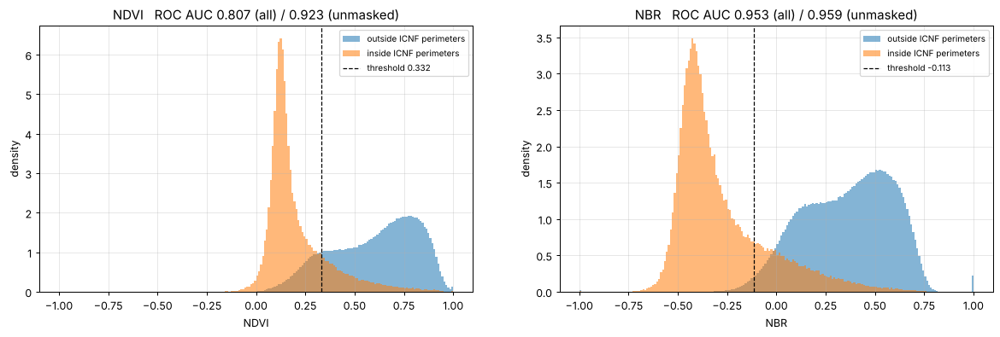

In [34]:
from sklearn.metrics import roc_auc_score

pos = rng.integers(0, valid.size, 3_000_000)
pos = pos[valid.ravel()[pos]]
y = ref_mask.ravel()[pos]
keep = ~mask.ravel()[pos]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (k, a) in zip(axes, IDX.items()):
    v = a.ravel()[pos]
    auc_all = roc_auc_score(y, -v)                  # lower value = more likely burned
    auc_keep = roc_auc_score(y[keep], -v[keep])
    vk, yk = v[keep], y[keep]
    ax.hist(vk[~yk], bins=200, range=(-1, 1), density=True, alpha=0.55, label="outside ICNF perimeters")
    ax.hist(vk[yk], bins=200, range=(-1, 1), density=True, alpha=0.55, label="inside ICNF perimeters")
    ax.axvline(THRESHOLDS[k], color="k", ls="--", lw=1, label=f"threshold {THRESHOLDS[k]:.3f}")
    ax.set(title=f"{k}   ROC AUC {auc_all:.3f} (all) / {auc_keep:.3f} (unmasked)", xlabel=k, ylabel="density")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

*Optional:* F1 across thresholds. It is tuned on the validation data itself, so its best value is optimistic. Use it
to see how sensitive each index is to the threshold choice, not to pick the threshold you report.

      best threshold  best F1
NDVI            0.17    0.530
NBR            -0.20    0.801


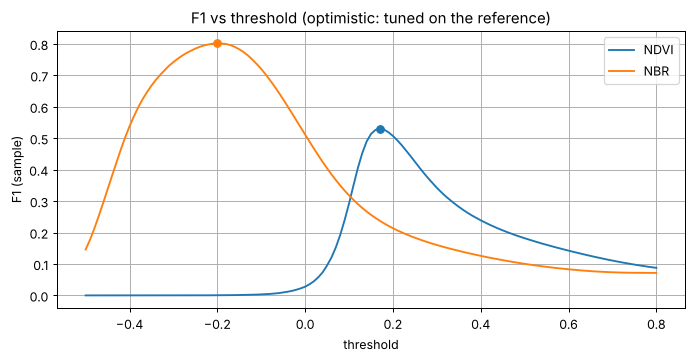

In [35]:
def f1(pred, ref):
    tp = np.count_nonzero(pred & ref); fp = np.count_nonzero(pred & ~ref); fn = np.count_nonzero(~pred & ref)
    return 2 * tp / (2 * tp + fp + fn)

ts = np.round(np.arange(-0.5, 0.81, 0.01), 2)
sweep = pd.DataFrame({k: [f1((a.ravel()[pos] < t) & keep, y) for t in ts] for k, a in IDX.items()}, index=ts)

ax = sweep.plot(figsize=(9, 4), grid=True, xlabel="threshold", ylabel="F1 (sample)",
                title="F1 vs threshold (optimistic: tuned on the reference)")
for k in sweep:
    ax.plot(sweep[k].idxmax(), sweep[k].max(), "o", color=ax.get_lines()[list(sweep).index(k)].get_color())
print(pd.DataFrame({"best threshold": sweep.idxmax(), "best F1": sweep.max().round(3)}))

### Your answers
1. Which index identifies burned areas better, NBR or NDVI, and why physically? (Think about what fire does to the
   NIR and SWIR signals, and what else besides burned ground has low NDVI.)
2. Which threshold did you choose, and how?
3. How well does your map agree with ICNF? Where do the commission and omission errors come from? Consider
   smoke and clouds, the fire that was still burning, small fires, and the 20 m SWIR resolution.